### Within-prior analysis

In [1]:
import pandas as pd
gene_level_local_metrics = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_local_overlap_allpair.csv')
gene_level_global_metrics = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_global_overlap_allpair.csv')

0.5668111328558513 0.0


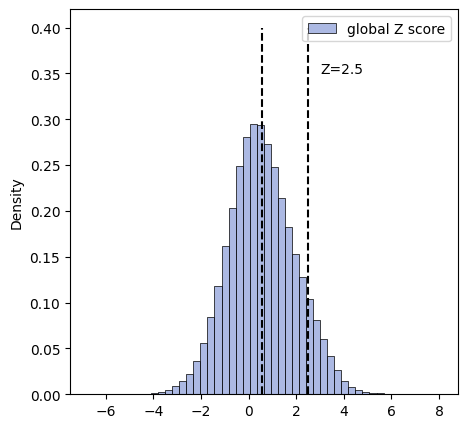

In [2]:
import seaborn as sns
import scipy
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

plt.figure(figsize=(5,5))
data = gene_level_global_metrics.set_index('gene').values.flatten()
sns.histplot(data, bins=50, label='global Z score', stat='density', color='#90A2DA')
#sns.histplot(gene_level_local_metrics.set_index('gene').values.flatten(), bins=100, label='local Z score', stat='density')
plt.vlines(x=2.5, ymin=0, ymax=0.4, color='black', linestyles='dashed')
plt.vlines(x=np.mean(data), ymin=0, ymax=0.4, color='black', linestyles='dashed')
plt.text(x=3, y=0.35, s='Z=2.5', color='black')
plt.legend()
_, p_value = stats.ttest_1samp(data, popmean=0)
print(np.mean(data), p_value)
#plt.savefig('../figure_out/Fig.3A_1.pdf')

1.2407911697810383 0.0


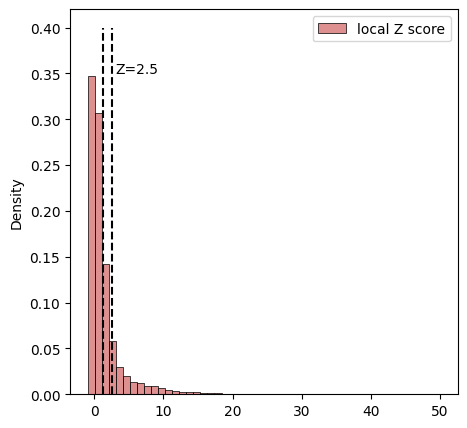

In [3]:
import seaborn as sns
import scipy
import matplotlib.pyplot as plt
plt.figure(figsize=(5,5))
data = gene_level_local_metrics.set_index('gene').values.flatten()
data = np.clip(data, a_min=data.min(), a_max=50)
sns.histplot(data, bins=50, label='local Z score', stat='density', color='#D36A6A')
plt.vlines(x=2.5, ymin=0, ymax=0.4, color='black', linestyles='dashed')
plt.vlines(x=np.mean(data), ymin=0, ymax=0.4, color='black', linestyles='dashed')
plt.text(x=3, y=0.35, s='Z=2.5', color='black')
plt.legend()
_, p_value = stats.ttest_1samp(data, popmean=0)
print(np.mean(data), p_value)
plt.legend()
#plt.savefig('../figure_out/Fig.3A_2.pdf')

In [4]:
import numpy as np
local_metrics = np.sum(gene_level_local_metrics.set_index('gene')>2.5, axis=0)/gene_level_local_metrics.shape[0]
global_metrics = np.sum(gene_level_global_metrics.set_index('gene')>2.5, axis=0)/gene_level_global_metrics.shape[0]
local_metrics = local_metrics.reset_index()
global_metrics = global_metrics.reset_index()

In [5]:
import numpy as np
kernel_ids = ['scGPT','genePT','MsigDB','StringDB','DepMap','Periscope','Untangled','Marbach']
global_mtx = pd.DataFrame(np.zeros((8,8)), index=kernel_ids, columns=kernel_ids)
local_mtx = pd.DataFrame(np.zeros((8,8)), index=kernel_ids, columns=kernel_ids)

for i, item in enumerate(global_metrics.values):
    x = item[0].split('_')[0]
    y = item[0].split('_')[1]
    val = item[1]
    global_mtx.loc[x, y] = val

for i, item in enumerate(local_metrics.values):
    x = item[0].split('_')[0]
    y = item[0].split('_')[1]
    val = item[1]
    local_mtx.loc[y, x] = val

global_mtx = global_mtx+global_mtx.T #+np.eye(N=8,M=8)
local_mtx = local_mtx+local_mtx.T #+np.eye(N=8,M=8)

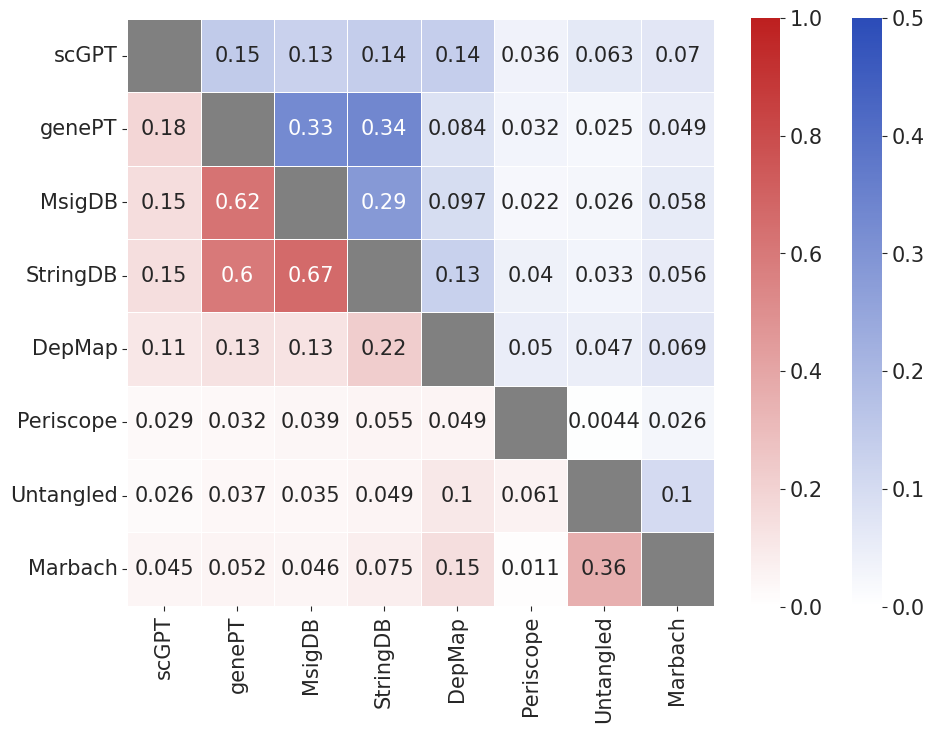

In [6]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

plt.rcParams["axes.facecolor"] = 'none'
plt.rc('font', size=15)
sns.set_style("ticks")
# Define colors as hex codes
colors = ['#FFFFFF', "#BD1F1F"] 
cmap_name = 'white_to_red'
cmap_reds = LinearSegmentedColormap.from_list(cmap_name, colors)

colors = ['#FFFFFF', "#2B4CB8"] 
cmap_name = 'white_to_blue'
cmap_blues = LinearSegmentedColormap.from_list(cmap_name, colors)
mask1 = np.tril(np.ones_like(global_mtx, dtype=bool))
mask2 = np.triu(np.ones_like(local_mtx, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(global_mtx, mask=mask1, cmap=cmap_blues, vmax=0.5, vmin=0, annot=True,
            square=True, linewidths=.5, cbar_kws={"shrink": .85, "pad":-.01}, ax=ax)
sns.heatmap(local_mtx, mask=mask2, cmap=cmap_reds, vmax=1, vmin=0, annot=True,
            square=True, linewidths=.5, cbar_kws={"shrink": .85}, ax=ax)

# the following lines color and hatch the axes background, only the diagonals are visible
ax.patch.set_facecolor('grey')
#plt.savefig('../figure_out/Fig.3B.pdf')
#plt.text(6,-.5,'Local Agreement')
#plt.text(8.5,0,'Global Agreement')
#ax.patch.set_hatch('xx')

/home/jhpark/anaconda3/envs/scgpt_env/lib/python3.9/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


<Figure size 1200x1200 with 0 Axes>

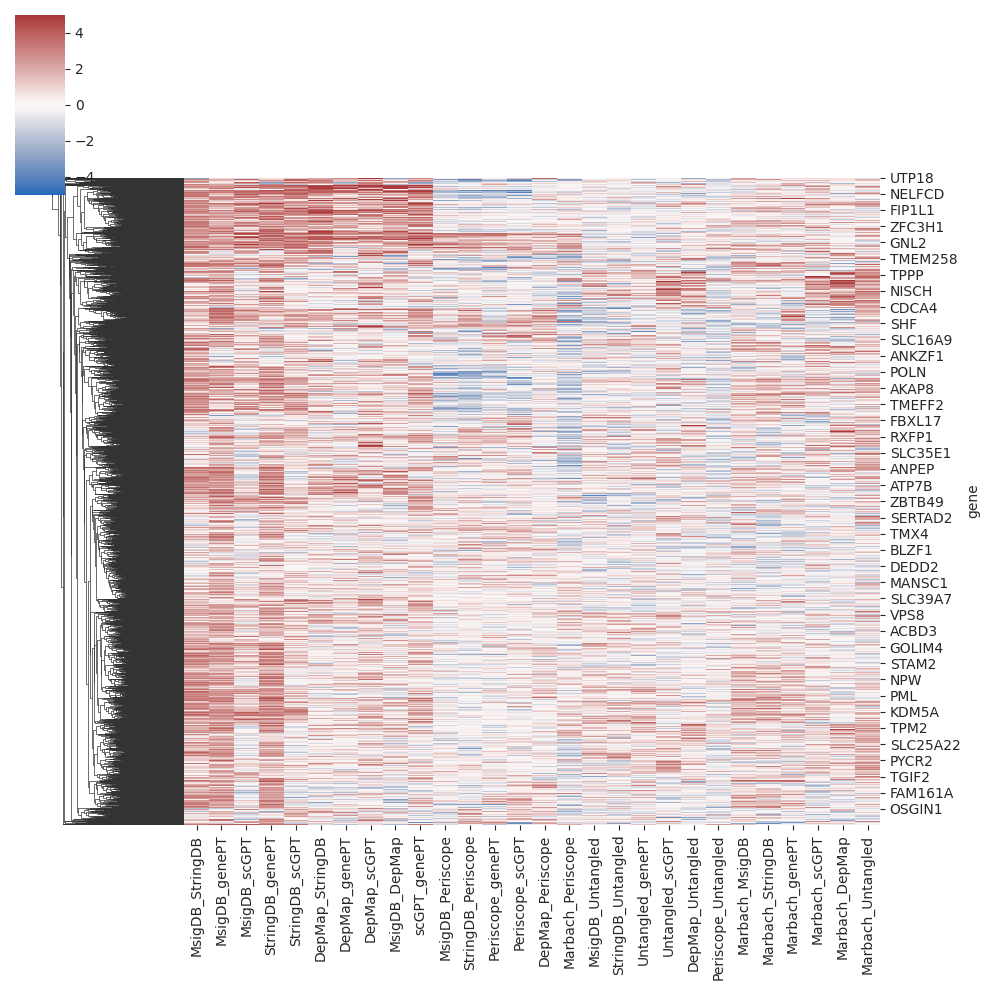

In [7]:
plt.figure(figsize=(12,12))
plt.rc('font', size=10)
col_order = [
    # Functional consensus
    "MsigDB_StringDB", "MsigDB_genePT", "MsigDB_scGPT", "StringDB_genePT", "StringDB_scGPT",
    "DepMap_StringDB", "DepMap_genePT", "DepMap_scGPT", "MsigDB_DepMap", "scGPT_genePT",
    # Periscope-involving
    "MsigDB_Periscope", "StringDB_Periscope", "Periscope_genePT", "Periscope_scGPT",
    "DepMap_Periscope", "Marbach_Periscope",
    # Untangled-involving
    "MsigDB_Untangled", "StringDB_Untangled", "Untangled_genePT",
    "Untangled_scGPT", "DepMap_Untangled", "Periscope_Untangled",
    # Marbach-involving
    "Marbach_MsigDB", "Marbach_StringDB", "Marbach_genePT",
    "Marbach_scGPT", "Marbach_DepMap", "Marbach_Untangled",
]
sns.clustermap(gene_level_global_metrics.set_index('gene')[col_order], row_cluster=True, col_cluster=False, vmin=-5, vmax=5, cmap='vlag')
#plt.savefig('../figure_out/Fig.3D_1_Heatmap.pdf')